# MP3: Grouping countries by the issues of ICT workers

DOM207 MP3 for the IMF. This notebook holds the complete analysis: it reads the raw file `data/raw/ICTIndiv.xlsx`, writes every table to `output/tables/` and every figure to `output/figures/`, and finally builds `report/MP3_Report.pdf`. Run it from the project folder, top to bottom.

## Setup

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re
import seaborn as sns
import subprocess
from pathlib import Path
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, silhouette_samples,
                             silhouette_score)
from statsmodels.stats.multicomp import pairwise_tukeyhsd

%matplotlib inline

In [2]:
ROOT = Path.cwd()

RAW_XLSX = ROOT / "data" / "raw" / "ICTIndiv.xlsx"

CLEAN_CSV = ROOT / "data" / "processed" / "ict_clean.csv"

FIG_DIR = ROOT / "output" / "figures"

TAB_DIR = ROOT / "output" / "tables"

VALUES_JSON = ROOT / "output" / "values.json"

ISSUES = ["FC", "JI", "SE", "WS", "WO", "WH", "WE", "TI", "TA"]

NAMES = {
    "FC": "Friendship circles", "JI": "Job insecurity", "SE": "Self-efficacy",
    "WS": "Work satisfaction", "WO": "Work overload", "WH": "Work-home conflict",
    "WE": "Work exhaustion", "TI": "Turnover intention", "TA": "Turnaway intention",
}

FS = [f"{i}_FS" for i in ISSUES]

S = [f"{i}_S" for i in ISSUES]

SCORES = {"FS": FS, "S": S}

SEED = 2026

K_RANGE = range(2, 11)

def save_values(new: dict) -> None:
    """Merge key numbers into values.json."""
    VALUES_JSON.parent.mkdir(parents=True, exist_ok=True)
    data = json.loads(VALUES_JSON.read_text()) if VALUES_JSON.exists() else {}
    data.update(new)
    VALUES_JSON.write_text(json.dumps(data, indent=2, sort_keys=True))

def write_table(name: str, df, floatfmt=".3f", index=False, numparse=True) -> None:
    """Write a table as Markdown and CSV. numparse=False keeps pre-formatted strings."""
    TAB_DIR.mkdir(parents=True, exist_ok=True)
    md = df.to_markdown(index=index, floatfmt=floatfmt, disable_numparse=not numparse)
    (TAB_DIR / f"{name}.md").write_text(md + "\n")
    df.to_csv(TAB_DIR / f"{name}.csv", index=index)

FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)
(ROOT / 'data' / 'processed').mkdir(parents=True, exist_ok=True)
VALUES_JSON.unlink(missing_ok=True)

## 1. Data preprocessing

Step 1: check the IMF file and prepare both score sets for clustering.

The factor scores (FSMean) are already standardised. The sum scores (Smean) sit on a
different scale for each issue, because each issue has a different number of items, so
they are z-scored before clustering. Nothing is imputed or dropped.

In [3]:
raw = pd.read_excel(RAW_XLSX, sheet_name="ClusterData")
raw.columns = [c.strip() for c in raw.columns]

checks = {
    "Countries": len(raw),
    "Columns": raw.shape[1],
    "Missing cells": int(raw.isna().sum().sum()),
    "Duplicate countries": int(raw["Country"].duplicated().sum()),
    "Duplicate codes": int(raw["Code"].duplicated().sum()),
    "Non-numeric score cells": int(sum(pd.to_numeric(raw[c], errors="coerce").isna().sum()
                                       for c in raw.columns if "mean" in c.lower())),
    "Codes missing from 1-46": ", ".join(str(c) for c in sorted(set(range(1, 47)) - set(raw["Code"]))),
}
write_table("data_checks", pd.DataFrame(checks.items(), columns=["Check", "Result"]),
            numparse=False)

df = raw[["Country", "Code", "Num"]].copy()
for i in ISSUES:
    df[f"{i}_FS"] = raw[f"{i}_FSMean"]
    s = raw[f"{i}_Smean"]
    df[f"{i}_Sraw"] = s
    df[f"{i}_S"] = (s - s.mean()) / s.std()

In [4]:
# Countries more than 2.5 standard deviations from the mean on any issue.
rows = []
for score, suffix in [("Factor score", "_FS"), ("Sum score", "_S")]:
    for i in ISSUES:
        col = df[f"{i}{suffix}"]
        z = (col - col.mean()) / col.std()
        for country, v in z[z.abs() > 2.5].items():
            rows.append({"Country": df.at[country, "Country"], "Issue": i, "Score": score,
                         "z": round(float(v), 2)})
extremes = pd.DataFrame(rows).sort_values(["Country", "Issue", "Score"])
write_table("extremes", extremes, floatfmt=".2f")

agreement = pd.DataFrame({"Issue": ISSUES,
                          "r(FS, S)": [df[f"{i}_FS"].corr(df[f"{i}_S"]) for i in ISSUES]})
write_table("score_agreement", agreement)

df.to_csv(CLEAN_CSV, index=False)
save_values({
    "n_countries": len(df), "n_resp_total": int(df["Num"].sum()),
    "n_resp_min": int(df["Num"].min()), "n_resp_max": int(df["Num"].max()),
    "resp_min_country": df.loc[df["Num"].idxmin(), "Country"],
    "resp_max_country": df.loc[df["Num"].idxmax(), "Country"],
    "r_fs_s_min": round(float(agreement["r(FS, S)"].min()), 3),
    "r_fs_s_max": round(float(agreement["r(FS, S)"].max()), 3),
})
print(f"prepared {len(df)} countries; {len(extremes)} extreme values flagged, none removed")

prepared 37 countries; 10 extreme values flagged, none removed


## 2. Data visualization and descriptive statistics

Step 2: descriptive statistics and the exploratory figures.

Each figure supports a decision: the heatmap shows that countries differ in a structured
way, the correlation matrix shows two blocks of issues, and the PCA map shows how many
groups to expect before any clustering is run.

In [5]:
def save(fig, name):
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200)
    plt.show()


def describe(x: pd.Series) -> dict:
    return {"Mean": x.mean(), "Median": x.median(), "Variance": x.var(), "SD": x.std(),
            "Min": x.min(), "Max": x.max(), "Range": x.max() - x.min(), "Skewness": x.skew(),
            "Kurtosis": x.kurt(), "Q1": x.quantile(.25), "Q3": x.quantile(.75)}

In [6]:
df = pd.read_csv(CLEAN_CSV).set_index("Country")

In [7]:
# Descriptive statistics of both scores (sum scores on their original scale).
rows = []
for i in ISSUES:
    rows.append({"Issue": f"{NAMES[i]} (FS)", **describe(df[f"{i}_FS"])})
    rows.append({"Issue": f"{NAMES[i]} (S)", **describe(df[f"{i}_Sraw"])})
rows.append({"Issue": "Respondents per country", **describe(df["Num"])})
write_table("descriptives", pd.DataFrame(rows), floatfmt=".2f")

corr = df[FS].corr()
corr.index = corr.columns = ISSUES
write_table("issue_correlations", corr.map(lambda v: f"{v:.2f}"), index=True, numparse=False)

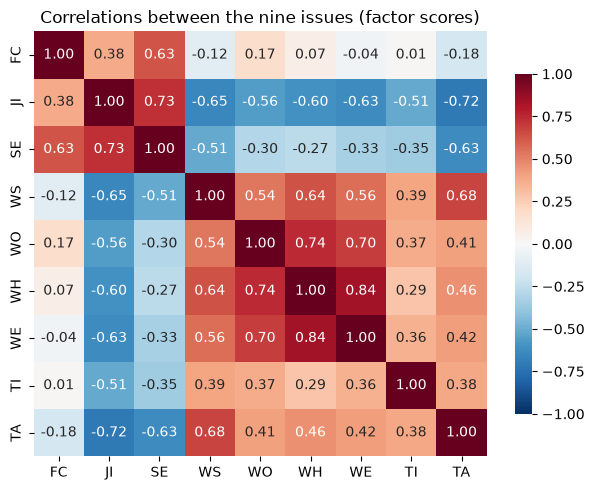

In [8]:
# Fig 1: correlations between the issues (two blocks).
fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax,
            cbar_kws={"shrink": .8})
ax.set_title("Correlations between the nine issues (factor scores)")
save(fig, "fig1_issue_correlations")

In [9]:
# PCA of the factor scores, used for the map and to order the heatmap.
pca = PCA(n_components=2).fit(df[FS])
pcs = pd.DataFrame(pca.transform(df[FS]), index=df.index, columns=["PC1", "PC2"])
if pca.components_[0][ISSUES.index("TA")] < 0:  # orient PC1 so strain points right
    pcs["PC1"] *= -1
    pca.components_[0] *= -1
pcs.to_csv(FIG_DIR.parent / "tables" / "pca_scores.csv")
loadings = pd.DataFrame(pca.components_.T, index=ISSUES, columns=["PC1", "PC2"])
write_table("pca_loadings", loadings.rename_axis("Issue"), index=True)

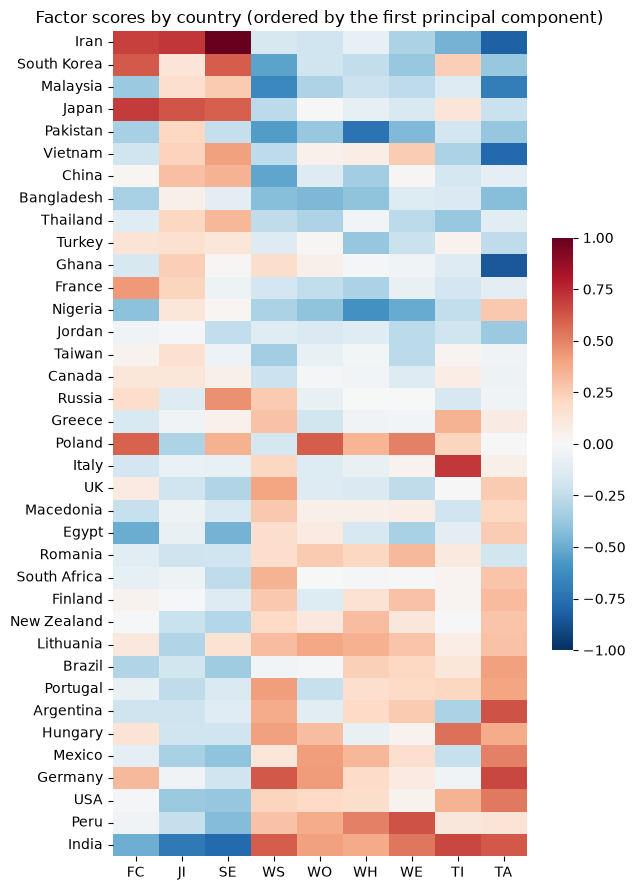

In [10]:
# Fig 2: country x issue heatmap, countries ordered along PC1.
order = pcs["PC1"].sort_values().index
heat = df.loc[order, FS]
heat.columns = ISSUES
fig, ax = plt.subplots(figsize=(6.5, 9))
sns.heatmap(heat, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .5})
ax.set(title="Factor scores by country (ordered by the first principal component)",
       xlabel="", ylabel="")
save(fig, "fig2_country_heatmap")

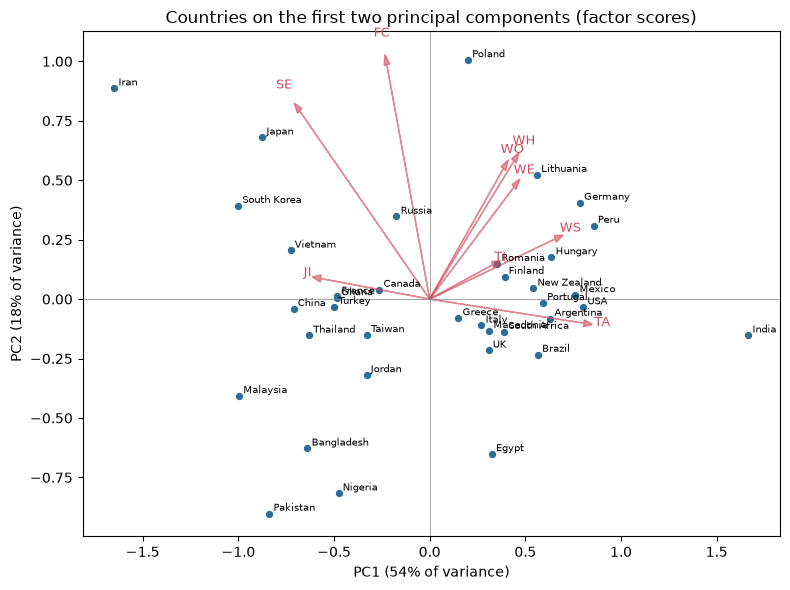

eda: PC1 54%, PC2 18%; 3 figures written


In [11]:
# Fig 3: PCA map of the countries with issue directions.
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(pcs["PC1"], pcs["PC2"], s=18, color="#2a6f97")
for c, (x, y) in pcs.iterrows():
    ax.annotate(c, (x, y), fontsize=7, xytext=(3, 2), textcoords="offset points")
scale = 1.6
for i, (lx, ly) in loadings.iterrows():
    ax.arrow(0, 0, lx * scale, ly * scale, color="#d1495b", alpha=.6, head_width=.03)
    ax.text(lx * scale * 1.12, ly * scale * 1.12, i, color="#d1495b", fontsize=9, ha="center")
ev = pca.explained_variance_ratio_
ax.axhline(0, color="grey", lw=.5)
ax.axvline(0, color="grey", lw=.5)
ax.set(xlabel=f"PC1 ({ev[0]:.0%} of variance)", ylabel=f"PC2 ({ev[1]:.0%} of variance)",
       title="Countries on the first two principal components (factor scores)")
save(fig, "fig3_pca_map")

save_values({"pca_ev1": round(float(ev[0]), 3), "pca_ev2": round(float(ev[1]), 3),
             "corr_wh_we": round(float(corr.loc["WH", "WE"]), 2),
             "corr_ji_se": round(float(corr.loc["JI", "SE"]), 2),
             "corr_ji_ta": round(float(corr.loc["JI", "TA"]), 2)})
print(f"eda: PC1 {ev[0]:.0%}, PC2 {ev[1]:.0%}; 3 figures written")

## 3. Clustering

Step 3: cluster the 37 countries on both score sets.

Standard workflow: the elbow method and the average silhouette choose k; Ward
hierarchical clustering and k-means are run at each candidate k on the factor scores
(FS) and on the standardised sum scores (S); the adjusted Rand index (ARI) and
cross-tabulations show whether the two scores, and the two methods, give the same groups.

In [12]:
BLUE, RED = "#2a6f97", "#d1495b"


CANDIDATES = [2, 3, 4]


def kmeans(X, k):
    return KMeans(k, n_init=200, random_state=SEED).fit(X)


def ward(X, k):
    return AgglomerativeClustering(k, linkage="ward").fit_predict(X)


def relabel(labels, reference):
    """Renumber clusters 1..k by the mean of a reference score, so labels read the same
    across methods and score sets (cluster 1 = lowest strain)."""
    order = pd.Series(reference).groupby(labels).mean().sort_values().index
    mapping = {old: new + 1 for new, old in enumerate(order)}
    return np.array([mapping[l] for l in labels])

In [13]:
df = pd.read_csv(CLEAN_CSV).set_index("Country")
strain = df[["WS_FS", "WO_FS", "WH_FS", "WE_FS", "TI_FS", "TA_FS"]].mean(axis=1).to_numpy()

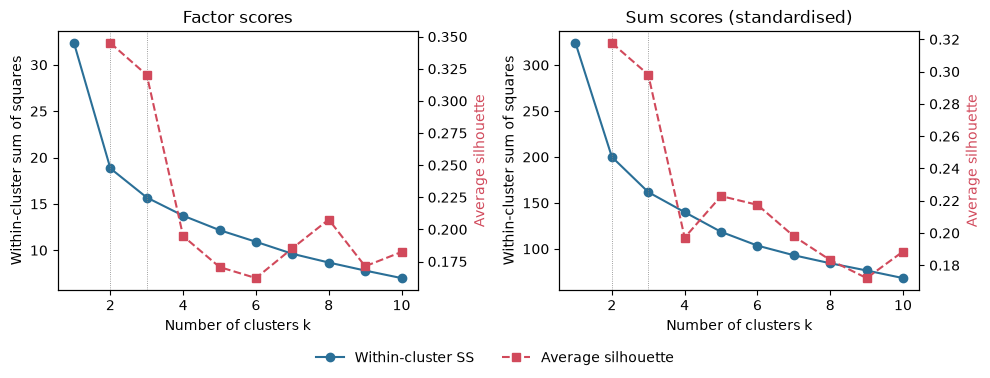

In [14]:
# 1. Choosing k: elbow (within-cluster sum of squares), silhouette, Calinski-Harabasz.
rows = []
for name, cols in SCORES.items():
    X = df[cols].to_numpy()
    for k in range(1, 11):
        km = kmeans(X, k)
        row = {"Score": name, "k": k, "WSS": km.inertia_}
        if k > 1:
            w = ward(X, k)
            row.update({"Silhouette (k-means)": silhouette_score(X, km.labels_),
                        "Silhouette (Ward)": silhouette_score(X, w),
                        "Calinski-Harabasz": calinski_harabasz_score(X, km.labels_),
                        "ARI k-means vs Ward": adjusted_rand_score(km.labels_, w)})
        rows.append(row)
choose = pd.DataFrame(rows)
choose["WSS drop %"] = (choose.groupby("Score")["WSS"].pct_change() * -100)
write_table("choose_k", choose.astype({"k": str}))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, (name, col) in zip(ax, [("FS", "Factor scores"), ("S", "Sum scores (standardised)")]):
    c = choose[choose.Score == name]
    a.plot(c["k"], c["WSS"], "o-", color=BLUE, label="Within-cluster SS")
    a.set(xlabel="Number of clusters k", ylabel="Within-cluster sum of squares", title=col)
    b = a.twinx()
    b.plot(c["k"], c["Silhouette (k-means)"], "s--", color=RED, label="Average silhouette")
    b.set_ylabel("Average silhouette", color=RED)
    b.grid(False)
    for k in (2, 3):
        a.axvline(k, color="grey", lw=.6, ls=":")
fig.legend(*[sum(x, []) for x in zip(*(a.get_legend_handles_labels() for a in
                                          [ax[0], ax[0].figure.axes[2]]))],
           loc="lower center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, .07, 1, 1))
fig.savefig(FIG_DIR / "fig4_elbow_silhouette.png", dpi=200)
plt.show()

In [15]:
# 2. Memberships at each candidate k, for both methods and both scores.
labels = pd.DataFrame(index=df.index)
for name, cols in SCORES.items():
    X = df[cols].to_numpy()
    for k in CANDIDATES:
        labels[f"{name}_km{k}"] = relabel(kmeans(X, k).labels_, strain)
        labels[f"{name}_ward{k}"] = relabel(ward(X, k), strain)
    labels[f"{name}_sil3"] = silhouette_samples(X, labels[f"{name}_km3"])
    labels[f"{name}_sil2"] = silhouette_samples(X, labels[f"{name}_km2"])
labels.to_csv(FIG_DIR.parent / "tables" / "memberships.csv")

In [16]:
# 3. Agreement: FS vs S and k-means vs Ward (adjusted Rand index).
ari = []
for k in CANDIDATES:
    ari.append({"k": k,
                "FS vs S (k-means)": adjusted_rand_score(labels[f"FS_km{k}"], labels[f"S_km{k}"]),
                "FS vs S (Ward)": adjusted_rand_score(labels[f"FS_ward{k}"], labels[f"S_ward{k}"]),
                "k-means vs Ward (FS)": adjusted_rand_score(labels[f"FS_km{k}"], labels[f"FS_ward{k}"]),
                "k-means vs Ward (S)": adjusted_rand_score(labels[f"S_km{k}"], labels[f"S_ward{k}"])})
write_table("ari", pd.DataFrame(ari).astype({"k": str}))

cross = pd.crosstab(labels["FS_km3"], labels["S_km3"], rownames=["FS cluster"], colnames=["S cluster"])
cross.columns = [f"S{c}" for c in cross.columns]
cross.index = [f"FS{c}" for c in cross.index]
write_table("crosstab_k3", cross.rename_axis("k = 3"), index=True, floatfmt=".0f")

members = []
for name in SCORES:
    for k in (2, 3):
        for c in sorted(labels[f"{name}_km{k}"].unique()):
            who = labels.index[labels[f"{name}_km{k}"] == c]
            members.append({"Score": name, "k": k, "Cluster": c, "n": len(who),
                            "Countries": ", ".join(who)})
write_table("members", pd.DataFrame(members), numparse=False)

In [17]:
# 4. Sensitivity: k-means without the two most extreme countries (Iran, Nigeria).
sens = []
keep = ~df.index.isin(["Iran", "Nigeria"])
for name, cols in SCORES.items():
    X = df.loc[keep, cols].to_numpy()
    for k in (2, 3):
        lab = relabel(kmeans(X, k).labels_, strain[keep])
        sens.append({"Score": name, "k": k,
                     "ARI with full-sample clusters": adjusted_rand_score(
                         labels.loc[keep, f"{name}_km{k}"], lab),
                     "Silhouette": silhouette_score(X, lab)})
write_table("sensitivity", pd.DataFrame(sens).astype({"k": str}))

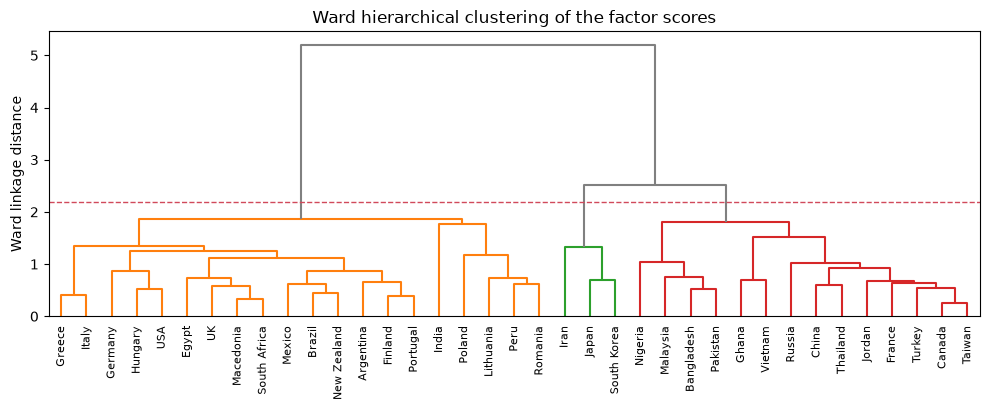

cluster: [{'k': 2, 'FS vs S (k-means)': 1.0, 'FS vs S (Ward)': 1.0, 'k-means vs Ward (FS)': 1.0, 'k-means vs Ward (S)': 1.0}, {'k': 3, 'FS vs S (k-means)': 0.78, 'FS vs S (Ward)': 0.78, 'k-means vs Ward (FS)': 1.0, 'k-means vs Ward (S)': 1.0}, {'k': 4, 'FS vs S (k-means)': 0.67, 'FS vs S (Ward)': 0.62, 'k-means vs Ward (FS)': 0.65, 'k-means vs Ward (S)': 0.55}]


In [18]:
# 5. Ward dendrogram on the factor scores.
Z = linkage(df[SCORES["FS"]].to_numpy(), method="ward")
fig, ax = plt.subplots(figsize=(10, 4.2))
cut = (Z[-2, 2] + Z[-3, 2]) / 2
dendrogram(Z, labels=df.index.tolist(), leaf_rotation=90, leaf_font_size=8,
           color_threshold=cut, above_threshold_color="grey", ax=ax)
ax.axhline(cut, color=RED, ls="--", lw=1)
ax.set(ylabel="Ward linkage distance", title="Ward hierarchical clustering of the factor scores")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_dendrogram.png", dpi=200)
plt.show()

c2 = choose.set_index(["Score", "k"])
save_values({
    **{f"wss_drop_{s}_{k}": round(float(c2.loc[(s, k), "WSS drop %"]), 1)
       for s in SCORES for k in range(2, 6)},
    **{f"sil_{s}_{k}": round(float(c2.loc[(s, k), "Silhouette (k-means)"]), 3)
       for s in SCORES for k in range(2, 6)},
    **{f"ari_k{r['k']}_fs_s": round(float(r["FS vs S (k-means)"]), 2) for r in ari},
    **{f"ari_k{r['k']}_km_ward_fs": round(float(r["k-means vs Ward (FS)"]), 2) for r in ari},
    "n_switch_k3": int((labels["FS_km3"] != labels["S_km3"]).sum()),
    "switch_k3": ", ".join(labels.index[labels["FS_km3"] != labels["S_km3"]]),
    "neg_sil_fs3": ", ".join(labels.index[labels["FS_sil3"] < 0]) or "none",
})
print("cluster:", pd.DataFrame(ari).round(2).to_dict("records"))

## 4. Do the clusters differ? ANOVA and profiles

Step 4: do the clusters really differ, and how?

One-way ANOVA on each issue across clusters, with Shapiro-Wilk (normality within each
cluster) and Levene (equal variances) as assumption checks and Kruskal-Wallis as the
non-parametric fallback. Tukey HSD shows which pairs of the three-cluster solution
differ. Cluster profiles (mean score per issue) give each group its character.

In [19]:
COLOURS = {1: "#2a6f97", 2: "#d1495b", 3: "#edae49"}


def stars(p):
    return "***" if p < .01 else "**" if p < .05 else "*" if p < .10 else ""


def anova_table(df, labels, score):
    rows = []
    for i in ISSUES:
        col = f"{i}_{score}"
        groups = [df.loc[labels == c, col] for c in sorted(labels.unique())]
        f, p = stats.f_oneway(*groups)
        lev_p = stats.levene(*groups, center="median").pvalue
        sw = [stats.shapiro(g).pvalue for g in groups if len(g) >= 3]
        kw_p = stats.kruskal(*groups).pvalue
        means = {f"Mean C{c}": g.mean() for c, g in zip(sorted(labels.unique()), groups)}
        ss_b = sum(len(g) * (g.mean() - df[col].mean()) ** 2 for g in groups)
        ss_t = ((df[col] - df[col].mean()) ** 2).sum()
        rows.append({"Issue": NAMES[i], **means, "F": f, "p (ANOVA)": p, "Eta²": ss_b / ss_t,
                     "Levene p": lev_p, "Min Shapiro p": min(sw), "p (Kruskal)": kw_p,
                     "Sig.": stars(p)})
    return pd.DataFrame(rows)

In [20]:
df = pd.read_csv(CLEAN_CSV).set_index("Country")
m = pd.read_csv(TAB_DIR / "memberships.csv", index_col=0).loc[df.index]
vals = {}

for score in SCORES:
    for k in (2, 3):
        t = anova_table(df, m[f"{score}_km{k}"], score)
        write_table(f"anova_{score}_k{k}", t, floatfmt=".3f")
        vals[f"anova_{score}_k{k}_nsig"] = int((t["p (ANOVA)"] < .05).sum())
        vals[f"anova_{score}_k{k}_nsig_kw"] = int((t["p (Kruskal)"] < .05).sum())
        vals[f"anova_{score}_k{k}_levene_fail"] = int((t["Levene p"] < .05).sum())
        vals[f"anova_{score}_k{k}_shapiro_fail"] = int((t["Min Shapiro p"] < .05).sum())
        for _, r in t.iterrows():
            key = [i for i in ISSUES if NAMES[i] == r["Issue"]][0]
            vals[f"eta_{score}_k{k}_{key}"] = round(float(r["Eta²"]), 2)
            vals[f"p_{score}_k{k}_{key}"] = float(r["p (ANOVA)"])

In [21]:
# Tukey HSD for the three-cluster solution of each score.
tk = []
for score in SCORES:
    lab = m[f"{score}_km3"]
    for i in ISSUES:
        res = pairwise_tukeyhsd(df[f"{i}_{score}"], lab)
        for row in res.summary().data[1:]:
            g1, g2, diff, p = row[0], row[1], row[2], row[3]
            tk.append({"Score": score, "Issue": NAMES[i], "Pair": f"C{g1} vs C{g2}",
                       "Mean difference": diff, "p (Tukey)": p, "Sig.": stars(p)})
tk = pd.DataFrame(tk)
write_table("tukey_k3", tk)
wide = tk.pivot_table(index="Issue", columns=["Score", "Pair"], values="p (Tukey)").loc[
    [NAMES[i] for i in ISSUES]]
wide.columns = [f"{s}: {p}" for s, p in wide.columns]
write_table("tukey_k3_wide", wide.map(lambda p: f"{p:.3f}{stars(p)}"), index=True, numparse=False)

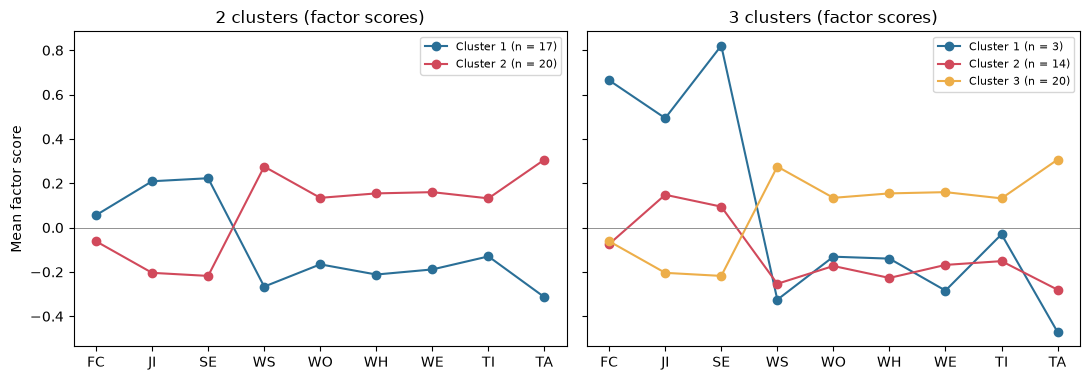

In [22]:
# Cluster profiles on the factor scores (k = 2 and k = 3).
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
x = np.arange(len(ISSUES))
for a, k in zip(ax, (2, 3)):
    lab = m[f"FS_km{k}"]
    for c in sorted(lab.unique()):
        means = df.loc[lab == c, [f"{i}_FS" for i in ISSUES]].mean()
        a.plot(x, means.values, "o-", color=COLOURS[c], label=f"Cluster {c} (n = {(lab == c).sum()})")
    a.axhline(0, color="grey", lw=.6)
    a.set_xticks(x, ISSUES)
    a.set(title=f"{k} clusters (factor scores)", ylabel="Mean factor score" if k == 2 else "")
    a.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6_profiles.png", dpi=200)
plt.show()

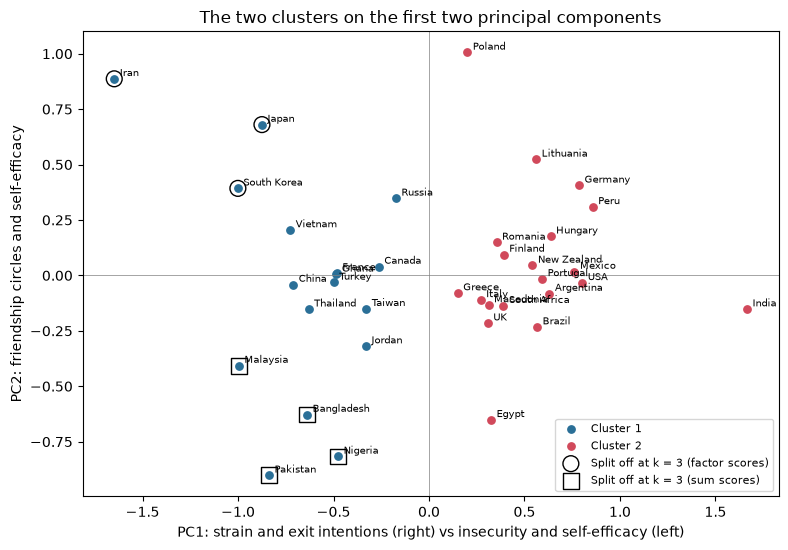

profile: {'anova_FS_k2_nsig': 8, 'anova_FS_k2_nsig_kw': 8, 'anova_FS_k2_levene_fail': 1, 'anova_FS_k2_shapiro_fail': 1, 'anova_FS_k3_nsig': 9, 'anova_FS_k3_nsig_kw': 9, 'anova_FS_k3_levene_fail': 0, 'anova_FS_k3_shapiro_fail': 3, 'anova_S_k2_nsig': 8, 'anova_S_k2_nsig_kw': 8, 'anova_S_k2_levene_fail': 0, 'anova_S_k2_shapiro_fail': 2, 'anova_S_k3_nsig': 9, 'anova_S_k3_nsig_kw': 9, 'anova_S_k3_levene_fail': 1, 'anova_S_k3_shapiro_fail': 2}


In [23]:
# PCA map coloured by the two-cluster solution, three-cluster subgroups marked.
pcs = pd.read_csv(TAB_DIR / "pca_scores.csv", index_col=0).loc[df.index]
fig, ax = plt.subplots(figsize=(8, 5.6))
for c in (1, 2):
    sel = m["FS_km2"] == c
    ax.scatter(pcs.loc[sel, "PC1"], pcs.loc[sel, "PC2"], s=28, color=COLOURS[c],
               label=f"Cluster {c}")
for name, marker, label in [("FS_km3", "o", "Split off at k = 3 (factor scores)"),
                            ("S_km3", "s", "Split off at k = 3 (sum scores)")]:
    sel = m[name] == 1
    ax.scatter(pcs.loc[sel, "PC1"], pcs.loc[sel, "PC2"], s=130, facecolors="none",
               edgecolors="black", marker=marker, lw=1, label=label)
for cn, (px, py) in pcs.iterrows():
    ax.annotate(cn, (px, py), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.axhline(0, color="grey", lw=.5)
ax.axvline(0, color="grey", lw=.5)
ax.set(xlabel="PC1: strain and exit intentions (right) vs insecurity and self-efficacy (left)",
       ylabel="PC2: friendship circles and self-efficacy",
       title="The two clusters on the first two principal components")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig7_cluster_map.png", dpi=200)
plt.show()

save_values(vals)
print("profile:", {k: v for k, v in vals.items() if "nsig" in k or "fail" in k})

## 5. Build the PDF report

Build report/MP3_Report.pdf from report/report.md with pandoc and pdflatex.

Two transformations are applied before pandoc runs:
- `{{table:name}}` is replaced by output/tables/name.md as a LaTeX longtable whose
  columns never wrap, and `{{float:name|caption}}` by the same table as a compact
  float, so included tables always match the latest analysis run.
- Every captioned pipe table becomes a floating table, so no table is split across
  pages; column widths follow the dash counts of the Markdown separator row.
Run `src/run_all.py` first.

In [24]:
REPORT_DIR = ROOT / "report"


NUMERIC = re.compile(r"^\(?-?[\d.]+\)?\**$")


def cell(text: str) -> str:
    for ch in "&%#_{}":
        text = text.replace(ch, "\\" + ch)
    text = re.sub(r"(?<![\w.])-(?=[\d.])", r"\\textminus{}", text)  # a minus sign never breaks a line
    return text.replace("χ²", r"$\chi^2$")


def md_to_latex(md: str) -> str:
    """Render a pipe table as a booktabs longtable with non-wrapping columns."""
    rows = [[c.strip() for c in line.strip().strip("|").split("|")] for line in md.splitlines()]
    header, body = rows[0], rows[2:]
    align = "".join("r" if all(NUMERIC.match(r[i]) for r in body if r[i]) else "l"
                    for i in range(len(header)))
    head = " & ".join(cell(h) for h in header) + r" \\"
    lines = [rf"\begin{{longtable}}{{@{{}}{align}@{{}}}}", r"\toprule", head, r"\midrule", r"\endhead"]
    # "{}" stops a cell that starts with "[" being read as an option of the previous "\\".
    lines += ["{}" + " & ".join(cell(c) for c in r) + r" \\" for r in body]
    lines += [r"\bottomrule", r"\end{longtable}"]
    return "```{=latex}\n" + "\n".join(lines) + "\n```"


def inline(text: str) -> str:
    """Convert a Markdown table cell to LaTeX, escaping only outside $...$ math."""
    parts = text.replace("\\*", "*").split("$")
    for i in range(0, len(parts), 2):
        parts[i] = (parts[i].replace("&", r"\&").replace("%", r"\%")
                    .replace("<", r"$<$").replace(">", r"$>$"))
    return "$".join(parts)


def float_table(m: re.Match) -> str:
    lines = m.group("table").strip().splitlines()
    rows = [[c.strip() for c in line.strip().strip("|").split("|")] for line in lines]
    header, seps, body = rows[0], rows[1], rows[2:]
    left = [i for i, sep in enumerate(seps) if not sep.endswith(":")]
    total = sum(len(seps[i]) for i in left)
    spec = ""
    for i, sep in enumerate(seps):
        if i in left:
            share = len(sep) * len(left) / total
            spec += rf">{{\raggedright\arraybackslash\hsize={share:.3f}\hsize}}X"
        else:
            spec += "r"
    out = [r"\begin{table}[htbp]", r"\centering", rf"\caption{{{inline(m.group('caption'))}}}",
           r"\small", rf"\begin{{tabularx}}{{\linewidth}}{{@{{}}{spec}@{{}}}}", r"\toprule",
           " & ".join(inline(c) for c in header) + r" \\", r"\midrule"]
    out += ["{}" + " & ".join(inline(c) for c in r) + r" \\" for r in body]
    out += [r"\bottomrule", r"\end{tabularx}", r"\end{table}"]
    return "```{=latex}\n" + "\n".join(out) + "\n```\n"


def float_tables(text: str) -> str:
    pattern = r"(?P<table>(?:^\|.*\|[ \t]*\n)+)\n?Table: (?P<caption>.+)\n"
    return re.sub(pattern, float_table, text, flags=re.M)


def md_to_float(md: str, caption: str) -> str:
    """Render a generated pipe table as a compact floating table (never split across pages)."""
    rows = [[c.strip() for c in line.strip().strip("|").split("|")] for line in md.splitlines()]
    header, body = rows[0], rows[2:]
    align = "l" + "r" * (len(header) - 1)
    lines = [r"\begin{table}[htbp]", r"\centering", rf"\caption{{{inline(caption)}}}",
             r"\footnotesize\setlength{\tabcolsep}{3.5pt}", rf"\begin{{tabular}}{{@{{}}{align}@{{}}}}",
             r"\toprule", " & ".join(cell(h) for h in header) + r" \\", r"\midrule"]
    lines += ["{}" + " & ".join(cell(c) for c in r) + r" \\" for r in body]
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    return "```{=latex}\n" + "\n".join(lines) + "\n```"


def include_tables(text: str) -> str:
    def sub(m):
        return md_to_latex((TAB_DIR / f"{m.group(1)}.md").read_text().strip())

    def sub_float(m):
        return md_to_float((TAB_DIR / f"{m.group(1)}.md").read_text().strip(), m.group(2))

    text = re.sub(r"\{\{float:([\w]+)\|([^}]+)\}\}", sub_float, text)
    return re.sub(r"\{\{table:([\w]+)\}\}", sub, text)

In [25]:
rendered = REPORT_DIR / "build" / "report.md"
rendered.parent.mkdir(exist_ok=True)
rendered.write_text(include_tables(float_tables((REPORT_DIR / "report.md").read_text())))
subprocess.run([
    "pandoc", str(rendered), "-o", str(REPORT_DIR / "MP3_Report.pdf"),
    "--pdf-engine=pdflatex", "--number-sections", f"--resource-path={ROOT}",
    "-H", str(REPORT_DIR / "header.tex"),
    "-V", "documentclass=article", "-V", "fontsize=10pt",
    "-V", "geometry:margin=2.2cm", "-V", "colorlinks=false",
], check=True)
print(f"report written to {REPORT_DIR / 'MP3_Report.pdf'}")

report written to /Users/rachitkumar/projects/coursework/ds/mp3/report/MP3_Report.pdf
